# Geología v0: geología de los sitios de la Luna y Marte frente a la Tierra

Hasta ahora los sitios objetivo (regiones Artemis, Exploration Zones y aterrizajes) se comparaban con la Tierra **solo por la forma
del terreno** (topografía). Esta capa añade **de qué roca está hecho el terreno** y la junta con la topografía.

| | Luna | Marte | Tierra |
|---|---|---|---|
| Mapa geológico | USGS *Unified Geologic Map of the Moon* 1:5 M (Fortezzo et al., 2020), 43 unidades | USGS SIM 3292 *Geologic Map of Mars* 1:20 M (Tanaka et al., 2014), 44 unidades | GLiM 1:3,75 M (ya en `glim_005.nc`) |
| Química (informativa) | Lunar Prospector GRS: FeO, TiO₂, Th… (píxeles de ~60 km) | Mars Odyssey GRS: Fe, Si, Cl, H₂O, K, Th (5°) | — |
| Sales | — | 640 depósitos de cloruros (Osterloo et al., 2010) | — |

**Método**
1. Cada sitio se mide en la misma zona que en topografía (polígono Artemis; círculo de 10 km en la Luna y de 25 km en Marte)
   con una rejilla de puntos: qué unidad geológica hay en cada punto.
2. Cada unidad se traduce a una **clase común** (basalto, piroclastos, anortosita, corteza mixta, sedimentos de agua, sedimentos de
   viento, derrubios, hielo). En la Luna, las unidades de cráteres y llanuras de impacto se reparten entre basalto y anortosita
   según el **FeO** del sitio (los mares tienen ~15–20 % de FeO; las tierras altas, ~4–6 %).
3. Cada clase común se traduce a la **mezcla de rocas de GLiM** que la representa (tabla editable).
4. **Distancia geológica** = 1 − fracción de roca compartida entre el sitio y la región de la Tierra (0 = misma composición).
5. **Distancia total** = media de la distancia topográfica (KS de pendiente y relieve) y la geológica. Un sitio tiene un
   **análogo completo** si topografía ≤ 0,2 **y** geología ≤ 0,4.

Se compara cada sitio con **todas** las regiones y análogos de la Tierra, de los dos perfiles: la geología decide qué es parecido,
no el perfil (así los mares lunares pueden emparejarse con llanuras de basalto del perfil de Marte, por ejemplo).

**Requisitos**: `topografia_sitios_v2` ejecutado con la versión que guarda `similitud_sitio_tierra_todas.csv` (secciones 1–6;
usa la caché, tarda pocos minutos), y `glim_005.nc` de Luna v0.3.

**Salidas**: `04_resultados/geologia_v0/` y `06_web/geologia_v0/geologia_sitios.json` (registrada en el manifest).

## 0. Instalación

In [1]:
!pip install -q pyogrio

## 1. Configuración

In [2]:
import os, re, io, json, glob, zipfile, shutil, datetime, unicodedata
import numpy as np, pandas as pd, requests, geopandas as gpd, xarray as xr, pyogrio
import matplotlib.pyplot as plt
from pyproj import CRS, Transformer
from rasterio import features
from rasterio.transform import from_origin
from shapely.geometry import shape, Point
from shapely import affinity, contains_xy
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "geologia_v0"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
BRUTOS = f"{BASE}/03_datos/brutos/geologia"
CACHE = f"{BASE}/03_datos/cache_api/geologia"
PROCESADOS = f"{BASE}/03_datos/procesados"
TMP = "/content/tmp/geologia"
for d in (RES, WEB, BRUTOS, CACHE, TMP):
    os.makedirs(d, exist_ok=True)

R_LUNA, R_MARTE = 1737400.0, 3396190.0
RADIO_LUNA_KM, RADIO_MARTE_KM = 10, 25          # las mismas zonas que en topografia_sitios
RADIO_ANALOGO_KM = 10                            # análogos conocidos de la Tierra (como en topografia_v1/v2)
PUNTOS_POR_RADIO = 15                            # rejilla de muestreo: paso = radio / 15 (~700 puntos por círculo)
UMBRAL_TOPO, UMBRAL_GEO = 0.2, 0.4               # análogo completo: topografía ≤ 0,2 y geología ≤ 0,4
FEO_TIERRAS_ALTAS, FEO_MARE = 6.0, 14.0          # % FeO: reparto de las unidades de impacto lunares entre anortosita y basalto
TOPO_SITIOS = f"{BASE}/04_resultados/topografia_sitios_v2"

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

SESION = requests.Session()
SESION.headers["User-Agent"] = "Mozilla/5.0 (Hackathon NASA Space Apps; Colab)"

def descargar(urls, destino, minimo_bytes=1000, es_zip=False):
    """Descarga el primer enlace que funcione a 'destino' (en Drive). Si ya existe y es válido, no descarga."""
    valido = lambda p: os.path.exists(p) and os.path.getsize(p) >= minimo_bytes and (not es_zip or zipfile.is_zipfile(p))
    if valido(destino):
        return destino
    for url in urls:
        try:
            tmp = f"{TMP}/{os.path.basename(destino)}.part"
            with SESION.get(url, stream=True, timeout=600) as r:
                r.raise_for_status()
                with open(tmp, "wb") as f:
                    for trozo in r.iter_content(1 << 22):
                        f.write(trozo)
            if valido(tmp):
                shutil.copy2(tmp, destino); os.remove(tmp)
                print(f"   ✔ {os.path.basename(destino)} ({os.path.getsize(destino) / 1e6:.1f} MB) desde {url[:70]}")
                return destino
            print(f"   ⚠ {url[:70]}: el archivo no es válido")
        except Exception as e:
            print(f"   ⚠ {url[:70]}: {e!r}"[:200])
    return None

entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
sitios = gpd.read_file(f"{BASE}/06_web/sitios_v0/sitios.geojson")
polar = gpd.read_file(f"{PROCESADOS}/sitios_luna_polar.gpkg")
print(sitios.groupby(["cuerpo", "tipo"]).size())

Mounted at /content/drive
cuerpo  tipo                     
luna    aterrizaje_planificado        1
        aterrizaje_robotico          22
        aterrizaje_tripulado          6
        region_aterrizaje_artemis     9
marte   aterrizaje_planificado        1
        aterrizaje_robotico          11
        exploration_zone             47
dtype: int64


## 2. Mapas geológicos de la Luna y Marte
Se descargan una vez a `03_datos/brutos/geologia/`. **Luna**: zip de 214 MB de USGS Astropedia. **Marte** (SIM 3292), por este
orden: (1) cualquier zip de SIM 3292 que ya esté en esa carpeta; (2) el zip *Database* de la página de descargas de USGS (~790 MB,
el notebook busca su nombre); (3) el servicio de mapas de NASA Trek (ArcGIS); (4) el servicio pygeoapi de USGS. Las vías 3 y 4
guardan los polígonos en `marte_sim3292.gpkg` y descargan por lotes que se reanudan si se cortan.

Si todo falla: abre https://pubs.usgs.gov/publication/sim3292, descarga **Database ZIP** y súbelo tal cual a
`03_datos/brutos/geologia/` (el nombre da igual si contiene «3292»).

In [3]:
import time
URLS_LUNA = ["https://asc-astropedia.s3.us-west-2.amazonaws.com/Moon/Geology/Unified_Geologic_Map_of_the_Moon_GIS_v2.zip"]
INDICE_MARTE = "https://pubs.usgs.gov/sim/3292/downloads/"
NOMBRES_ZIP_MARTE = ["sim3292_database.zip", "SIM3292_database.zip", "sim3292_gis.zip", "SIM3292_MarsGlobalGeologicGIS_20M.zip",
                     "sim3292_MarsGlobalGeologicGIS_20M.zip"]
TREK_MARTE = "https://trek.nasa.gov/mars/arcgis/rest/services/SIM3292_Global_Geology/MapServer"
PYGEOAPI_MARTE = "https://astrogeology.usgs.gov/pygeoapi/collections/mars/sim3292_global_geologic_map/units/items"
GEO_MARTE = "+proj=longlat +R=3396190 +no_defs"
FUENTE_MAPA = {}

def capas_vectoriales(carpeta):
    # Todas las capas de polígonos (shapefiles y geodatabases) dentro de una carpeta
    out = []
    rutas = glob.glob(f"{carpeta}/**/*.shp", recursive=True) + glob.glob(f"{carpeta}/**/*.gdb", recursive=True)
    for ruta in rutas:
        try:
            for nombre, tipo in pyogrio.list_layers(ruta):
                if tipo and "polygon" in str(tipo).lower():
                    info = pyogrio.read_info(ruta, layer=nombre)
                    out.append({"ruta": ruta, "capa": nombre, "n": info["features"], "campos": list(info["fields"])})
        except Exception as e:
            print(f"   (se omite {os.path.basename(ruta)}: no se puede abrir con GDAL)")
    return out

PAT_SIMBOLO = [r"unitsymbol", r"first_unitsymbol", r"unit_symbol", r"unitsymb", r"unit", r"first_unit", r"symbol", r".*symbol.*", r".*unit.*"]

def elegir_campos(df):
    # Símbolo: el campo que se llama como un símbolo; nombre: el campo de texto más largo (los nombres pueden venir truncados)
    texto = [c for c in df.columns if c != "geometry" and (df[c].dtype == object or pd.api.types.is_string_dtype(df[c]))
             and not re.match(r"shape_", c, re.I)]
    sim = None
    for p in PAT_SIMBOLO:
        sim = next((c for c in texto if re.fullmatch(p, c, flags=re.I)), None)
        if sim:
            break
    if sim is None and texto:
        sim = min(texto, key=lambda c: df[c].astype(str).str.len().mean())
    otros = [c for c in texto if c != sim]
    nom = max(otros, key=lambda c: df[c].astype(str).str.len().mean()) if otros else None
    return sim, nom

def normalizar(gdf, sim, nom, cuerpo):
    assert sim, f"{cuerpo}: no encuentro el campo con el símbolo de la unidad. Campos: {list(gdf.columns)}"
    gdf = gdf.rename(columns={sim: "unidad", **({nom: "nombre_unidad"} if nom else {})})
    if "nombre_unidad" not in gdf.columns:
        gdf["nombre_unidad"] = ""
    gdf = gdf[["unidad", "nombre_unidad", "geometry"]].copy()
    gdf["unidad"] = gdf["unidad"].astype(str).str.strip()
    gdf["nombre_unidad"] = gdf["nombre_unidad"].fillna("").astype(str).str.strip()
    gdf = gdf[gdf.geometry.notna() & ~gdf.geometry.is_empty]
    print(f"{cuerpo}: símbolo '{sim}' · nombre '{nom}' · ejemplos:")
    display(gdf.drop(columns="geometry").drop_duplicates("unidad").head(6))
    return gdf

def leer_zip(cuerpo, zip_):
    destino = f"{TMP}/{cuerpo}"
    if not capas_vectoriales(destino):
        with zipfile.ZipFile(zip_) as z:
            for m in z.namelist():
                if not re.search(r"\.(tif|tiff|jpg|jpeg|png|pdf|mxd|ovr|aux\.xml)$", m, re.I):
                    z.extract(m, destino)
            for m in [m for m in z.namelist() if m.lower().endswith(".zip")]:        # zips dentro del zip
                with zipfile.ZipFile(f"{destino}/{m}") as z2:
                    z2.extractall(f"{destino}/{os.path.splitext(m)[0]}")
    capas = capas_vectoriales(destino)
    assert capas, f"No encuentro capas de polígonos dentro de {zip_}"
    prefer = [c for c in capas if re.search(r"geounit|geology|units?$", c["capa"], re.I) and not re.search(r"label|anno", c["capa"], re.I)]
    capa = max(prefer or capas, key=lambda c: c["n"])
    print(f"{cuerpo}: capa '{capa['capa']}' ({capa['n']:,} polígonos) · campos {capa['campos']}")
    gdf = gpd.read_file(capa["ruta"], layer=capa["capa"], engine="pyogrio")
    FUENTE_MAPA[cuerpo] = os.path.basename(zip_)
    return normalizar(gdf, *elegir_campos(gdf), cuerpo)

def zip_marte():
    # 1) un zip de SIM 3292 ya subido a Drive
    for z in glob.glob(f"{BRUTOS}/*.zip"):
        if re.search(r"3292|mars", os.path.basename(z), re.I) and zipfile.is_zipfile(z):
            print(f"marte: uso {os.path.basename(z)} (ya en Drive)")
            return z
    # 2) página de descargas de USGS: busca los .zip del índice y prueba nombres conocidos
    urls = []
    try:
        r = SESION.get(INDICE_MARTE, timeout=60)
        urls = [requests.compat.urljoin(INDICE_MARTE, h) for h in re.findall(r'href="([^"]+\.zip)"', r.text, re.I)]
        print(f"marte: zips en el índice de USGS: {[os.path.basename(u) for u in urls] or 'ninguno'}")
    except Exception as e:
        print(f"   ⚠ índice de USGS: {e!r}"[:150])
    urls += [INDICE_MARTE + n for n in NOMBRES_ZIP_MARTE if INDICE_MARTE + n not in urls]
    return descargar(urls, f"{BRUTOS}/sim3292_database.zip", minimo_bytes=1_000_000, es_zip=True)

def pedir(url, params, intentos=4):
    for k in range(intentos):
        try:
            r = SESION.get(url, params=params, timeout=300)
            r.raise_for_status()
            return r.json()
        except Exception as e:
            if k == intentos - 1:
                raise
            print(f"   reintento {k + 1} ({e!r})"[:120]); time.sleep(10 * (k + 1))

def anillos_a_geom(anillos):
    from shapely.geometry import Polygon, MultiPolygon, LinearRing
    conchas, huecos = [], []
    for a in anillos:
        (huecos if LinearRing(a).is_ccw else conchas).append(Polygon(a))         # ArcGIS: exterior en sentido horario
    for h in huecos:
        for k, c in enumerate(conchas):
            if c.contains(h.representative_point()):
                conchas[k] = c.difference(h); break
    return conchas[0] if len(conchas) == 1 else MultiPolygon([g for c in conchas for g in getattr(c, "geoms", [c])])

def marte_trek():
    cache_dir = f"{CACHE}/trek"; os.makedirs(cache_dir, exist_ok=True)
    capas = pedir(f"{TREK_MARTE}/layers", {"f": "json"})["layers"]
    capa = next(c for c in capas if c.get("geometryType") == "esriGeometryPolygon")
    sr = capa.get("extent", {}).get("spatialReference", {})
    print(f"marte (NASA Trek): capa {capa['id']} '{capa['name']}' · referencia espacial {sr}")
    ids = sorted(pedir(f"{TREK_MARTE}/{capa['id']}/query", {"where": "1=1", "returnIdsOnly": "true", "f": "json"})["objectIds"])
    filas = []
    for k in range(0, len(ids), 100):
        ruta = f"{cache_dir}/lote_{k:05d}.json"
        if os.path.exists(ruta):
            d = json.load(open(ruta))
        else:
            d = pedir(f"{TREK_MARTE}/{capa['id']}/query", {"objectIds": ",".join(map(str, ids[k:k + 100])), "outFields": "*",
                                                           "returnGeometry": "true", "f": "json"})
            json.dump(d, open(ruta, "w"))
        for f in d["features"]:
            if f.get("geometry", {}).get("rings"):
                filas.append({**f["attributes"], "geometry": anillos_a_geom(f["geometry"]["rings"])})
        print(f"   {min(k + 100, len(ids))}/{len(ids)} polígonos")
    wkt = sr.get("wkt") or ""
    proyectado = "PROJCS" in wkt.upper()
    gdf = gpd.GeoDataFrame(filas, geometry="geometry", crs=CRS.from_wkt(wkt) if proyectado else GEO_MARTE)
    return gdf

def marte_pygeoapi():
    cache_dir = f"{CACHE}/pygeoapi"; os.makedirs(cache_dir, exist_ok=True)
    feats, off = [], 0
    while True:
        ruta = f"{cache_dir}/lote_{off:05d}.json"
        if os.path.exists(ruta):
            lote = json.load(open(ruta))
        else:
            lote = pedir(PYGEOAPI_MARTE, {"f": "json", "limit": 100, "offset": off}).get("features", [])
            json.dump(lote, open(ruta, "w"))
        if not lote:
            break
        feats += lote; off += len(lote)
        print(f"   {off} polígonos")
    return gpd.GeoDataFrame.from_features(feats, crs=GEO_MARTE)

MAPA = {"luna": None, "marte": None}
z = descargar(URLS_LUNA, f"{BRUTOS}/Unified_Geologic_Map_of_the_Moon_GIS_v2.zip", minimo_bytes=1_000_000, es_zip=True)
assert z, f"No se pudo descargar el mapa de la Luna: súbelo a {BRUTOS}/ desde {URLS_LUNA[0]}"
MAPA["luna"] = leer_zip("luna", z)

GPKG_MARTE = f"{BRUTOS}/marte_sim3292.gpkg"
if os.path.exists(GPKG_MARTE):
    MAPA["marte"] = gpd.read_file(GPKG_MARTE); FUENTE_MAPA["marte"] = os.path.basename(GPKG_MARTE)
else:
    z = zip_marte()
    if z:
        MAPA["marte"] = leer_zip("marte", z)
    for nombre, funcion in (("NASA Trek", marte_trek), ("pygeoapi de USGS", marte_pygeoapi)):
        if MAPA["marte"] is not None:
            break
        try:
            print(f"marte: descargando los polígonos de {nombre}…")
            g = funcion()
            MAPA["marte"] = normalizar(g, *elegir_campos(g), "marte"); FUENTE_MAPA["marte"] = nombre
        except Exception as e:
            print(f"   ⚠ {nombre}: {e!r}"[:200])
    assert MAPA["marte"] is not None, ("No se pudo descargar el mapa de Marte. Abre https://pubs.usgs.gov/publication/sim3292, "
                                       f"descarga 'Database ZIP' y súbelo a {BRUTOS}/ ; luego vuelve a ejecutar esta celda.")
    MAPA["marte"].to_file(GPKG_MARTE, driver="GPKG")
for cuerpo, g in MAPA.items():
    print(f"{cuerpo}: {len(g):,} polígonos · {g.unidad.nunique()} unidades · fuente {FUENTE_MAPA.get(cuerpo)} · CRS: {str(g.crs)[:70]}")

/usr/local/lib/python3.13/dist-packages/pyogrio/core.py:169: RuntimeWarning: Lines_Group1_EQ layer has a /content/tmp/geologia/luna/Unified_Geologic_Map_of_the_Moon_GIS/Lunar_GIS/LunarAnnoGeodatabase_08-14-2013.gdb/a00000009.gdbtable.cdf file using Compressed Data Format (CDF) that is unhandled by the OpenFileGDB driver, but could be handled by the FileGDB driver.
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
/usr/local/lib/python3.13/dist-packages/pyogrio/core.py:169: RuntimeWarning: Lines_Group2_EQ layer has a /content/tmp/geologia/luna/Unified_Geologic_Map_of_the_Moon_GIS/Lunar_GIS/LunarAnnoGeodatabase_08-14-2013.gdb/a0000000a.gdbtable.cdf file using Compressed Data Format (CDF) that is unhandled by the OpenFileGDB driver, but could be handled by the FileGDB driver.
  return ogr_list_layers(get_vsi_path_or_buffer(path_or_buffer))
/usr/local/lib/python3.13/dist-packages/pyogrio/core.py:169: RuntimeWarning: Lines_Group1_SP layer has a /content/tmp/geologia/luna/Unif

   (se omite LunarAnnoGeodatabase_08-14-2013.gdb: no se puede abrir con GDAL)
   (se omite Global_Geology_of_the_Moon_5M_03-02-2020.gdb: no se puede abrir con GDAL)
luna: capa 'GeoUnits' (12,247 polígonos) · campos ['FIRST_Unit', 'FIRST_Un_1', 'FIRST_Un_2', 'Shape_Leng', 'Shape_Area', 'AREA_GEO']
luna: símbolo 'FIRST_Unit' · nombre 'FIRST_Un_2' · ejemplos:


,unidad,nombre_unidad
0,Ec,Crater Unit
1,Ic2,Upper Crater Unit
4,Ib,Basin Undivided Unit
5,Im2,Upper Mare Unit
6,Iohs,"Orientale Hevelius Formation, Secondary Crater..."
7,Nbl,Basin Lineated Unit


luna: 12,247 polígonos · 49 unidades · fuente Unified_Geologic_Map_of_the_Moon_GIS_v2.zip · CRS: PROJCS["Moon2000_EquidistantCylindrical_clon0",GEOGCS["GCS_Moon_2000",
marte: 1,311 polígonos · 44 unidades · fuente marte_sim3292.gpkg · CRS: GEOGCS["GCS_Mars_2000_Sphere",DATUM["Mars_2000_(Sphere)",SPHEROID["Mar


## 3. De unidad geológica a clase común y de clase común a rocas de GLiM
Reglas (editables): la tabla de cada cuerpo se guarda en `04_resultados/geologia_v0/mapa_unidades_<cuerpo>.csv`. **Si se edita la
columna `clases` y se guarda como `03_datos/brutos/geologia/mapa_unidades_<cuerpo>.csv`, el notebook usa esa versión.**

- **Luna**: unidades de mare → basalto; mantos oscuros → piroclastos; domos y conos → basalto; el resto (cráteres, cuencas, tierras
  altas, llanuras de impacto) → `impacto`, que se reparte entre basalto y anortosita con el FeO del sitio (sección 5).
- **Marte**: por el grupo del símbolo de SIM 3292 (h tierras altas, t transición, l tierras bajas, b cuenca, a delantal,
  i impacto, v volcánico, p polar) y la descripción de la unidad.

In [4]:
CLASES = {
    "basalto": "lava basáltica (mares lunares, llanuras y volcanes de Marte)",
    "piroclastos": "ceniza y piroclastos (mantos oscuros lunares, depósitos de ceniza)",
    "anortosita": "corteza de las tierras altas lunares (anortosita y brechas de impacto)",
    "corteza_mixta": "corteza antigua de Marte: brechas de impacto con lava y sedimentos",
    "sedimentos_agua": "sedimentos de ríos, lagos e inundaciones",
    "sedimentos_viento": "sedimentos sueltos o de viento (dunas, loess, polvo)",
    "derrubios": "derrubios de ladera y deslizamientos",
    "hielo": "hielo con polvo (casquetes y depósitos polares)",
    "evaporitas": "sales (cloruros, sulfatos)",
}
# Mezcla de clases de GLiM que representa cada clase común (cada fila suma 1). GLiM: su sedimentos no consolidados,
# ss siliciclásticas, sm sedimentarias mixtas, py piroclásticas, sc carbonatos, ev evaporitas, mt metamórficas,
# pa/pi/pb plutónicas ácidas/intermedias/básicas (pb incluye gabros y anortositas), va/vi/vb volcánicas, ig hielo.
CLASES_GLIM = ["su", "ss", "sm", "py", "sc", "ev", "mt", "pa", "pi", "pb", "va", "vi", "vb", "ig", "wb", "nd"]
UTILES_GLIM = [c for c in CLASES_GLIM if c not in ("wb", "nd")]
EQUIVALENCIA = {
    "basalto":           {"vb": 0.85, "vi": 0.10, "py": 0.05},
    "piroclastos":       {"py": 0.70, "vb": 0.20, "su": 0.10},
    "anortosita":        {"pb": 0.60, "mt": 0.20, "pi": 0.10, "su": 0.10},
    "corteza_mixta":     {"vb": 0.35, "sm": 0.20, "ss": 0.15, "mt": 0.15, "su": 0.15},
    "sedimentos_agua":   {"ss": 0.45, "sm": 0.25, "su": 0.20, "ev": 0.05, "sc": 0.05},
    "sedimentos_viento": {"su": 0.80, "ss": 0.20},
    "derrubios":         {"su": 0.60, "ss": 0.20, "vb": 0.20},
    "hielo":             {"ig": 0.90, "su": 0.10},
    "evaporitas":        {"ev": 0.80, "su": 0.20},
}
for k, v in EQUIVALENCIA.items():
    assert abs(sum(v.values()) - 1) < 1e-9 and set(v) <= set(UTILES_GLIM), k
pd.DataFrame(EQUIVALENCIA).T.reindex(columns=UTILES_GLIM).fillna(0).to_csv(f"{RES}/equivalencia_clases_glim.csv")

def clases_luna(sim, nombre):
    n = f"{nombre} {sim}".lower()
    if "mare" in n or re.fullmatch(r"(e|i|ei|ie)m\d?", sim.lower()):
        return {"basalto": 1.0}
    if "dark mantl" in n or "pyroclast" in n:
        return {"piroclastos": 1.0}
    if re.search(r"\bdome|\bcone|volcan|sinuous rille", n):
        return {"basalto": 1.0}
    return {"impacto": 1.0}            # cráteres, cuencas, tierras altas, llanuras de impacto: se reparte con el FeO

def clases_marte(sim, nombre):
    m = re.match(r"^(e|m|l)?(AH|HN|AN|A|H|N)([a-z]*)$", sim)
    g = m.group(3) if m else ""
    edad = (m.group(2) if m else "")
    d = nombre.lower()
    if g in ("v", "vf"):                      return {"basalto": 1.0}
    if g in ("ve", "he"):                     return {"basalto": 0.7, "piroclastos": 0.3}
    if g in ("h", "hu", "hm", "i"):           return {"corteza_mixta": 1.0}
    if g in ("t", "to"):                      return {"sedimentos_agua": 1.0}
    if g == "tu":
        return {"sedimentos_viento": 0.6, "piroclastos": 0.4} if edad == "AH" else {"derrubios": 0.5, "sedimentos_agua": 0.5}
    if g == "l":
        return {"sedimentos_viento": 0.7, "hielo": 0.3} if edad == "A" else {"sedimentos_agua": 1.0}
    if g == "b":
        return {"sedimentos_agua": 0.5, "sedimentos_viento": 0.3, "hielo": 0.2} if "ice" in d else \
               {"sedimentos_agua": 0.6, "sedimentos_viento": 0.2, "basalto": 0.2}
    if g == "a":                              return {"derrubios": 1.0}
    if g in ("pc", "p", "pe"):                return {"hielo": 1.0}
    if g == "pu":
        return {"hielo": 0.8, "sedimentos_viento": 0.2} if edad == "A" else {"hielo": 0.5, "sedimentos_viento": 0.5}
    if g == "pd":                             return {"sedimentos_viento": 1.0}
    # sin grupo reconocido: por la descripción
    if re.search(r"lava|volcan|flood", d):    return {"basalto": 1.0}
    if re.search(r"\bice\b", d):              return {"hielo": 1.0}
    if re.search(r"eolian|dune", d):          return {"sedimentos_viento": 1.0}
    if re.search(r"fluvial|lacustrine|outflow", d): return {"sedimentos_agua": 1.0}
    if re.search(r"impact|breccia|crater", d): return {"corteza_mixta": 1.0}
    return {}

REGLAS = {"luna": clases_luna, "marte": clases_marte}
MAPEO = {}
for cuerpo, g in MAPA.items():
    if g.crs is not None and not CRS.from_user_input(g.crs).is_geographic:
        area = g.geometry.area
    else:
        area = g.geometry.area * np.cos(np.radians(g.geometry.centroid.y))     # aproximada, solo para ordenar
    tabla = (g.assign(_a=area).groupby("unidad").agg(nombre_unidad=("nombre_unidad", "first"), poligonos=("unidad", "size"),
                                                     area_rel=("_a", "sum")).reset_index())
    tabla["area_rel"] = (tabla.area_rel / tabla.area_rel.sum() * 100).round(2)
    tabla["clases"] = [json.dumps(REGLAS[cuerpo](r.unidad, r.nombre_unidad)) for r in tabla.itertuples()]
    editado = f"{BRUTOS}/mapa_unidades_{cuerpo}.csv"
    if os.path.exists(editado):
        e = pd.read_csv(editado)[["unidad", "clases"]]
        tabla = tabla.drop(columns="clases").merge(e, on="unidad", how="left")
        tabla["clases"] = tabla.clases.fillna("{}")
        print(f"{cuerpo}: usando la tabla editada {editado}")
    tabla.sort_values("area_rel", ascending=False).to_csv(f"{RES}/mapa_unidades_{cuerpo}.csv", index=False)
    MAPEO[cuerpo] = {r.unidad: json.loads(r.clases) for r in tabla.itertuples()}
    sin = tabla[tabla.clases == "{}"]
    print(f"\n{cuerpo}: {len(tabla)} unidades · sin clase: {len(sin)} ({sin.area_rel.sum():.1f} % del área)")
    display(tabla.sort_values("area_rel", ascending=False)[["unidad", "nombre_unidad", "area_rel", "clases"]].head(60))


luna: 49 unidades · sin clase: 0 (0.0 % del área)


,unidad,nombre_unidad,area_rel,clases
43,Nt,Terra Unit,11.72,"{""impacto"": 1.0}"
24,Im2,Upper Mare Unit,9.26,"{""basalto"": 1.0}"
40,Nc,Crater Unit,8.85,"{""impacto"": 1.0}"
47,pNc,Crater Unit,8.80,"{""impacto"": 1.0}"
32,Ip,Plains Unit,6.21,"{""impacto"": 1.0}"
14,Ic2,Upper Crater Unit,4.53,"{""impacto"": 1.0}"
45,pNb,Basin Undivided Unit,4.44,"{""impacto"": 1.0}"
48,pNt,Terra Unit,4.39,"{""impacto"": 1.0}"
26,Iohi,"Orientale Hevelius Formation, Inner Facies Unit",3.47,"{""impacto"": 1.0}"
4,Ec,Crater Unit,3.39,"{""impacto"": 1.0}"


/tmp/ipykernel_2372/420453870.py:77: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area = g.geometry.area * np.cos(np.radians(g.geometry.centroid.y))     # aproximada, solo para ordenar
/tmp/ipykernel_2372/420453870.py:77: UserWarning: Geometry is in a geographic CRS. Results from 'centroid' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area = g.geometry.area * np.cos(np.radians(g.geometry.centroid.y))     # aproximada, solo para ordenar



marte: 44 unidades · sin clase: 0 (0.0 % del área)


,unidad,nombre_unidad,area_rel,clases
42,mNh,Middle Noachian highland unit,24.17,"{""corteza_mixta"": 1.0}"
35,lHl,Late Hesperian lowland unit,10.89,"{""sedimentos_agua"": 1.0}"
27,eNh,Early Noachian highland unit,9.77,"{""corteza_mixta"": 1.0}"
2,AHv,Amazonian and Hesperian volcanic,9.59,"{""basalto"": 1.0}"
39,lNh,Late Noachian highland unit,5.57,"{""corteza_mixta"": 1.0}"
0,AHi,Amazonian and Hesperian impact unit,5.23,"{""corteza_mixta"": 1.0}"
26,eHv,Early Hesperian volcanic unit,3.85,"{""basalto"": 1.0}"
25,eHt,Early Hesperian transition unit,2.45,"{""sedimentos_agua"": 1.0}"
32,lAv,Late Amazonian volcanic unit,2.26,"{""basalto"": 1.0}"
41,mAl,Middle Amazonian lowland unit,1.98,"{""sedimentos_viento"": 0.7, ""hielo"": 0.3}"


## 4. Qué unidad hay en cada sitio
Rejilla de puntos dentro de la zona de cada sitio (paso = radio / 15). Los puntos se pasan al sistema de coordenadas del mapa
geológico y se cruzan con sus polígonos.

In [5]:
def puntos_circulo(lon, lat, radio_km, R):
    aeqd = CRS.from_proj4(f"+proj=aeqd +lat_0={lat} +lon_0={lon} +R={R} +units=m +no_defs")
    geo = CRS.from_proj4(f"+proj=longlat +R={R} +no_defs")
    paso = radio_km * 1000 / PUNTOS_POR_RADIO
    v = np.arange(-radio_km * 1000, radio_km * 1000 + paso, paso)
    xx, yy = np.meshgrid(v, v); ok = np.hypot(xx, yy) <= radio_km * 1000
    lo, la = Transformer.from_crs(aeqd, geo, always_xy=True).transform(xx[ok], yy[ok])
    return np.asarray(lo), np.asarray(la)

def puntos_poligono(geom, crs_poligono, n=40):
    x0, y0, x1, y1 = geom.bounds
    paso = max(x1 - x0, y1 - y0) / n
    xx, yy = np.meshgrid(np.arange(x0, x1 + paso, paso), np.arange(y0, y1 + paso, paso))
    ok = contains_xy(geom, xx, yy)
    c = CRS.from_user_input(crs_poligono)
    lo, la = Transformer.from_crs(c, c.geodetic_crs, always_xy=True).transform(xx[ok], yy[ok])
    return np.asarray(lo), np.asarray(la)

def a_capa(cuerpo, lon, lat):
    """Puntos (lon, lat del cuerpo) → coordenadas del mapa geológico."""
    g = MAPA[cuerpo]
    R = R_LUNA if cuerpo == "luna" else R_MARTE
    c = CRS.from_user_input(g.crs) if g.crs is not None else CRS.from_proj4(f"+proj=longlat +R={R} +no_defs")
    if c.is_geographic:
        x0, _, x1, _ = g.total_bounds
        lon = np.where(lon < 0, lon + 360, lon) if x1 > 180 else ((lon + 180) % 360) - 180
        return lon, lat
    x, y = Transformer.from_crs(c.geodetic_crs, c, always_xy=True).transform(lon, lat)
    return np.asarray(x), np.asarray(y)

def unidades_en(cuerpo, lon, lat):
    x, y = a_capa(cuerpo, lon, lat)
    ok = np.isfinite(x) & np.isfinite(y)
    pts = gpd.GeoDataFrame({"i": np.arange(ok.sum())}, geometry=gpd.points_from_xy(x[ok], y[ok]), crs=MAPA[cuerpo].crs)
    j = gpd.sjoin(pts, MAPA[cuerpo][["unidad", "geometry"]], how="left", predicate="intersects").drop_duplicates("i")
    u = np.full(len(lon), None, dtype=object); u[np.where(ok)[0]] = j.sort_values("i").unidad.values
    return u

por_nombre = {r.region: r.geometry for r in polar.itertuples()}
MUESTRA = {}
for r in sitios.itertuples():
    if r.tipo == "region_aterrizaje_artemis":
        lon, lat = puntos_poligono(por_nombre[r.nombre], polar.crs)
    else:
        radio = RADIO_LUNA_KM if r.cuerpo == "luna" else RADIO_MARTE_KM
        lon, lat = puntos_circulo(r.geometry.x, r.geometry.y, radio, R_LUNA if r.cuerpo == "luna" else R_MARTE)
    MUESTRA[r.id] = {"cuerpo": r.cuerpo, "lon": lon, "lat": lat, "unidad": unidades_en(r.cuerpo, lon, lat)}
cob = pd.Series({k: float(np.mean([u is not None and u == u for u in v["unidad"]])) for k, v in MUESTRA.items()})
print(f"Puntos por sitio: {int(np.median([len(v['lon']) for v in MUESTRA.values()]))} (mediana) · "
      f"sitios con < 90 % de puntos con unidad: {(cob < 0.9).sum()}")
if (cob < 0.9).any():
    display(sitios.set_index("id").loc[cob[cob < 0.9].index, ["nombre", "cuerpo", "tipo"]].assign(cobertura=cob[cob < 0.9].round(2)))

Puntos por sitio: 701 (mediana) · sitios con < 90 % de puntos con unidad: 0


## 5. Química de la superficie (informativa) y cloruros de Marte
- **Luna**: Lunar Prospector GRS (Prettyman et al., 2006), píxeles de igual área de 2° (~60 km). El **FeO** decide cómo se reparten
  las unidades de impacto entre basalto y anortosita; TiO₂ y Th se guardan como información.
- **Marte**: Mars Odyssey GRS (Boynton et al., 2007), celdas de 5° suavizadas; solo latitudes bajas y medias.
- **Cloruros**: los ~640 depósitos de Osterloo et al. (2010), en la tabla de Leask y Ehlmann (2021, CaltechDATA, CC0).

In [6]:
URL_LPGRS = ["https://pds-geosciences.wustl.edu/lunar/lp-l-grs-5-elem-abundance-v1/lp_9001/data/lpgrs_high1_elem_abundance_2deg.tab",
             "https://pds-geosciences.wustl.edu/Lunar/lp-l-grs-5-elem-abundance-v1/lp_9001/data/lpgrs_high1_elem_abundance_2deg.tab"]
COLS_LP = ["pixel", "min_lat", "max_lat", "min_lon", "max_lon", "am", "neutron_den",
           "MgO", "Al2O3", "SiO2", "CaO", "TiO2", "FeO", "K_ppm", "Th_ppm", "U_ppm"]
ruta = descargar(URL_LPGRS, f"{CACHE}/lpgrs_high1_elem_abundance_2deg.tab", minimo_bytes=1_000_000)
lp = pd.read_csv(ruta, sep=r"\s+", header=None, usecols=range(16), names=COLS_LP)
for c in ["MgO", "Al2O3", "SiO2", "CaO", "TiO2", "FeO"]:
    lp[c] = lp[c] * 100                                          # g/g → % en peso
print(f"Lunar Prospector GRS: {len(lp)} píxeles · FeO {lp.FeO.min():.1f}–{lp.FeO.max():.1f} %")

def quimica_luna(lon, lat):
    paso = max(len(lon) // 40, 1)                                 # ~40 puntos bastan (píxeles de ~60 km)
    lon, lat = ((np.asarray(lon)[::paso] + 180) % 360) - 180, np.asarray(lat)[::paso]
    filas = []
    for a, b in zip(lon, lat):
        m = (lp.min_lat <= b) & (b < lp.max_lat) & (lp.min_lon <= a) & (a < lp.max_lon)
        if not m.any() and b <= lp.min_lat.min() + 1e-9:
            m = lp.min_lat == lp.min_lat.min()
        if m.any():
            filas.append(lp[m].iloc[0])
    if not filas:
        return {}
    d = pd.DataFrame(filas)
    return {"FeO_pct": round(d.FeO.mean(), 1), "TiO2_pct": round(d.TiO2.mean(), 2), "Th_ppm": round(d.Th_ppm.mean(), 1)}

BASE_GRS = "https://pds-geosciences.wustl.edu/ody/ody-m-grs-5-elements-v1/odgm_xxxx/data/smoothed/"
GRS = {}
for el, archivo in {"Fe": "fe", "Si": "si", "Cl": "cl", "H2O": "h2o", "K": "k", "Th": "th"}.items():
    ruta = descargar([BASE_GRS + f"{archivo}_sr_5x5.tab", BASE_GRS.replace("/data/", "/DATA/") + f"{archivo.upper()}_SR_5X5.TAB"],
                     f"{CACHE}/grs_{archivo}_sr_5x5.tab", minimo_bytes=10_000)
    if ruta is None:
        print(f"   ⚠ Mars GRS {el}: sin datos"); continue
    t = pd.read_csv(ruta, sep=r"\s+", header=None, usecols=range(3), names=["lat", "lon", "valor"])
    t.loc[t.valor > 9999, "valor"] = np.nan
    t["lon"] = t.lon % 360
    GRS[el] = t
print("Mars GRS:", {k: f"{v.valor.notna().sum()} celdas con dato" for k, v in GRS.items()})

def quimica_marte(lon, lat):
    out = {}
    r = np.radians(np.asarray(lon))
    lo, la = float(np.degrees(np.arctan2(np.sin(r).mean(), np.cos(r).mean())) % 360), float(np.mean(lat))   # media circular
    for el, t in GRS.items():
        d = np.hypot(t.lat - la, ((t.lon - lo + 180) % 360) - 180)
        v = t.valor.iloc[int(np.argmin(d))]
        out[f"{el}_pct"] = None if pd.isna(v) else round(float(v), 3 if el in ("K", "Th") else 2)
    return out

URL_CL = ["https://data.caltech.edu/records/kasms-vp209/files/Leask_and_Ehlmann_2021_2010_osterloo_chl_pts_w_tanaka_2014_age.csv?download=1"]
ruta = descargar(URL_CL, f"{CACHE}/cloruros_osterloo2010.csv", minimo_bytes=5_000)
CLORUROS = None
if ruta:
    t = pd.read_csv(ruta)
    clat = next((c for c in t.columns if re.search(r"lat", c, re.I)), None)
    clon = next((c for c in t.columns if re.search(r"lon", c, re.I)), None)
    if clat and clon:
        CLORUROS = pd.DataFrame({"lat": pd.to_numeric(t[clat], errors="coerce"), "lon": pd.to_numeric(t[clon], errors="coerce") % 360}).dropna()
        print(f"Cloruros: {len(CLORUROS)} depósitos (columnas {clat}, {clon})")
    else:
        print("   ⚠ La tabla de cloruros no trae columnas de latitud/longitud:", list(t.columns)[:12])

def cloruros_cerca(lon, lat, radio_km):
    if CLORUROS is None:
        return None
    la1, lo1 = np.radians(lat), np.radians(lon % 360)
    la2, lo2 = np.radians(CLORUROS.lat.values), np.radians(CLORUROS.lon.values)
    a = np.sin((la2 - la1) / 2) ** 2 + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2
    return int((2 * R_MARTE / 1000 * np.arcsin(np.sqrt(a)) <= radio_km).sum())

Lunar Prospector GRS: 11306 píxeles · FeO 0.0–30.7 %
Mars GRS: {'Fe': '1508 celdas con dato', 'Si': '1508 celdas con dato', 'Cl': '1508 celdas con dato', 'H2O': '1508 celdas con dato', 'K': '2592 celdas con dato', 'Th': '2592 celdas con dato'}
Cloruros: 642 depósitos (columnas Lat2, Lon2)


## 6. Composición de cada sitio
Fracción de cada clase común en la zona del sitio. En la Luna, la parte `impacto` se reparte con el FeO:
`basalto = (FeO − 6) / (14 − 6)` (entre 0 y 1) y el resto anortosita.

In [7]:
filas = []
for r in sitios.itertuples():
    m = MUESTRA[r.id]
    u = pd.Series(m["unidad"]).dropna()
    quim = quimica_luna(m["lon"], m["lat"]) if r.cuerpo == "luna" else quimica_marte(m["lon"], m["lat"])
    comp = {}
    for unidad, frac in u.value_counts(normalize=True).items():
        for clase, w in MAPEO[r.cuerpo].get(unidad, {}).items():
            comp[clase] = comp.get(clase, 0) + frac * w
    if "impacto" in comp:
        feo = quim.get("FeO_pct")
        f_mare = 0.0 if feo is None else float(np.clip((feo - FEO_TIERRAS_ALTAS) / (FEO_MARE - FEO_TIERRAS_ALTAS), 0, 1))
        imp = comp.pop("impacto")
        comp["basalto"] = comp.get("basalto", 0) + imp * f_mare
        comp["anortosita"] = comp.get("anortosita", 0) + imp * (1 - f_mare)
    total = sum(comp.values())
    comp = {k: v / total for k, v in comp.items()} if total else {}
    fila = {"id": r.id, "nombre": r.nombre, "cuerpo": r.cuerpo, "tipo": r.tipo,
            "cobertura_mapa": round(len(u) / max(len(m["unidad"]), 1), 2), "fraccion_clasificada": round(total, 2),
            "unidades": "; ".join(f"{k} {v:.0%}" for k, v in u.value_counts(normalize=True).head(3).items()),
            "clase_dominante": max(comp, key=comp.get) if comp else None,
            **{f"f_{c}": round(comp.get(c, 0), 3) for c in CLASES}, **quim}
    if r.cuerpo == "marte":
        fila["cloruros_25km"] = cloruros_cerca(r.geometry.x, r.geometry.y, RADIO_MARTE_KM)
        fila["cloruros_100km"] = cloruros_cerca(r.geometry.x, r.geometry.y, 100)
    filas.append(fila)
geo_sit = pd.DataFrame(filas)
geo_sit.to_csv(f"{RES}/geologia_sitios.csv", index=False)
cols = ["nombre", "tipo", "unidades", "clase_dominante"] + [f"f_{c}" for c in CLASES if geo_sit[f"f_{c}"].sum() > 0]
print("Luna"); display(geo_sit[geo_sit.cuerpo == "luna"][cols + ["FeO_pct", "TiO2_pct", "Th_ppm"]])
print("Marte"); display(geo_sit[geo_sit.cuerpo == "marte"][cols + [c for c in geo_sit.columns if c.endswith("_pct") and c not in ("FeO_pct", "TiO2_pct")] + ["cloruros_25km", "cloruros_100km"]])
print(geo_sit.groupby(["cuerpo", "clase_dominante"]).size())

Luna


,nombre,tipo,unidades,clase_dominante,f_basalto,f_piroclastos,f_anortosita,f_corteza_mixta,f_sedimentos_agua,f_sedimentos_viento,f_derrubios,f_hielo,FeO_pct,TiO2_pct,Th_ppm
0,Peak Near Cabeus B,region_aterrizaje_artemis,pNc 76%; pNb 24%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,5.1,0.07,0.9
1,Haworth,region_aterrizaje_artemis,pNb 73%; pNc 27%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,5.3,0.23,0.9
2,Malapert Massif,region_aterrizaje_artemis,pNbm 81%; pNb 19%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,4.8,0.00,0.9
3,Mons Mouton Plateau,region_aterrizaje_artemis,pNb 66%; pNbm 20%; pNc 15%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,4.7,0.07,0.6
4,Mons Mouton,region_aterrizaje_artemis,pNb 85%; pNc 15%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,5.0,0.25,0.7
5,Nobile Rim 1,region_aterrizaje_artemis,pNc 93%; pNb 7%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,5.1,0.09,0.7
6,Nobile Rim 2,region_aterrizaje_artemis,pNc 98%; Nc 2%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,4.8,0.22,0.7
7,de Gerlache Rim 2,region_aterrizaje_artemis,pNb 68%; Nc 32%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,5.3,0.21,0.7
8,Slater Plain,region_aterrizaje_artemis,Ntp 55%; pNb 45%,anortosita,0.000,0.0,1.000,0.0,0.0,0.0,0.0,0.0,5.2,0.12,0.8
9,Apollo 11,aterrizaje_tripulado,Im2 100%,basalto,1.000,0.0,0.000,0.0,0.0,0.0,0.0,0.0,12.2,3.44,1.5


Marte


,nombre,tipo,unidades,clase_dominante,f_basalto,f_piroclastos,f_anortosita,f_corteza_mixta,f_sedimentos_agua,f_sedimentos_viento,f_derrubios,f_hielo,Fe_pct,Si_pct,Cl_pct,H2O_pct,K_pct,Th_pct,cloruros_25km,cloruros_100km
37,Mars 3,aterrizaje_robotico,lNh 91%; eNh 9%,corteza_mixta,0.000,0.000,0.0,1.000,0.000,0.000,0.000,0.00,13.80,19.88,0.51,3.48,0.374,0.753,0.0,0.0
38,Viking 1,aterrizaje_robotico,Hto 100%,sedimentos_agua,0.000,0.000,0.0,0.000,1.000,0.000,0.000,0.00,15.49,20.96,0.37,2.62,0.320,0.615,0.0,0.0
39,Viking 2,aterrizaje_robotico,lHl 90%; AHi 10%,sedimentos_agua,0.000,0.000,0.0,0.098,0.902,0.000,0.000,0.00,14.34,20.86,0.52,4.58,0.458,0.735,0.0,0.0
40,Mars Pathfinder,aterrizaje_robotico,Hto 97%; Nhu 3%,sedimentos_agua,0.000,0.000,0.0,0.029,0.971,0.000,0.000,0.00,16.83,20.51,0.39,3.00,0.398,0.760,0.0,0.0
41,Spirit (MER-A),aterrizaje_robotico,eHv 100%,basalto,1.000,0.000,0.0,0.000,0.000,0.000,0.000,0.00,15.79,19.70,0.69,7.34,0.329,0.606,0.0,0.0
42,Opportunity (MER-B),aterrizaje_robotico,HNhu 100%,corteza_mixta,0.000,0.000,0.0,1.000,0.000,0.000,0.000,0.00,15.17,19.86,0.57,5.34,0.310,0.608,0.0,0.0
43,Phoenix,aterrizaje_robotico,lHl 63%; mAl 37%,sedimentos_agua,0.000,0.000,0.0,0.000,0.635,0.256,0.000,0.11,NaN,NaN,NaN,NaN,0.266,0.400,0.0,0.0
44,Curiosity (MSL),aterrizaje_robotico,AHi 55%; Htu 45%,corteza_mixta,0.000,0.000,0.0,0.555,0.223,0.000,0.223,0.00,15.09,20.43,0.58,5.42,0.305,0.584,0.0,0.0
45,InSight,aterrizaje_robotico,eHt 100%,sedimentos_agua,0.000,0.000,0.0,0.000,1.000,0.000,0.000,0.00,16.26,20.28,0.62,5.16,0.279,0.564,0.0,0.0
46,Perseverance (Mars 2020),aterrizaje_robotico,HNt 75%; mNhm 25%,sedimentos_agua,0.000,0.000,0.0,0.245,0.755,0.000,0.000,0.00,16.62,20.61,0.39,3.53,0.316,0.599,0.0,0.0


cuerpo  clase_dominante
luna    anortosita         16
        basalto            22
marte   basalto             8
        corteza_mixta      31
        derrubios           1
        sedimentos_agua    19
dtype: int64


## 7. Composición de las regiones de la Tierra (GLiM)
Las mismas regiones candidatas y análogos conocidos (círculo de 10 km) que en topografía, con `glim_005.nc` (rejilla de 0,05°).

In [8]:
glim = xr.open_dataset(f"{PROCESADOS}/glim_005.nc")
FR = glim.frac.values                                # (clase, lat ascendente, lon), en %
LAT, LON = glim.lat.values, glim.lon.values
PASO = float(np.round(LAT[1] - LAT[0], 6))
assert list(glim.clase.values) == CLASES_GLIM, glim.clase.values

def circulo_grados(lon, lat, radio_km):
    rlat = radio_km / 111.32
    return affinity.scale(Point(lon, lat).buffer(rlat, 64), xfact=1 / max(np.cos(np.radians(lat)), 0.05), yfact=1)

def glim_region(g):
    oeste, sur, este, norte = g.bounds
    i0, i1 = max(int(np.floor((sur - LAT[0]) / PASO)) - 1, 0), min(int(np.ceil((norte - LAT[0]) / PASO)) + 2, len(LAT))
    j0, j1 = max(int(np.floor((oeste - LON[0]) / PASO)) - 1, 0), min(int(np.ceil((este - LON[0]) / PASO)) + 2, len(LON))
    tr = from_origin(LON[j0] - PASO / 2, LAT[i1 - 1] + PASO / 2, PASO, PASO)          # filas de norte a sur
    dentro = features.geometry_mask([g], out_shape=(i1 - i0, j1 - j0), transform=tr, invert=True, all_touched=g.area < 0.05)[::-1]
    v = FR[:, i0:i1, j0:j1][:, dentro].astype(float).mean(axis=1) if dentro.any() else np.zeros(len(CLASES_GLIM))
    return dict(zip(CLASES_GLIM, v / 100))

filas = []
for cuerpo in ["luna", "marte"]:
    info = entrada["cuerpos"][cuerpo]
    gj = json.load(open(f"{BASE}/06_web/{info['carpeta']}/regiones.geojson", encoding="utf-8"))
    for ft in gj["features"]:
        p = ft["properties"]
        filas.append({"region_id": p["id"], "perfil": cuerpo, "tipo_tierra": "region_candidata", "region": p.get("region"),
                      **glim_region(shape(ft["geometry"]))})
    an = json.load(open(f"{BASE}/06_web/{info['carpeta']}/analogos.geojson", encoding="utf-8"))
    for ft in an["features"]:
        p = ft["properties"]
        ok = (p.get("tipo") in ("analogo_luna", "impacto")) if cuerpo == "luna" else (p.get("verificacion") == "verificada")
        if not ok or not ft.get("geometry"):
            continue
        lon, lat = ft["geometry"]["coordinates"][:2]
        slug = re.sub(r"[^a-z0-9]+", "-", unicodedata.normalize("NFKD", p["nombre"]).encode("ascii", "ignore").decode().lower()).strip("-")[:40]
        filas.append({"region_id": f"analogo-{cuerpo}-{slug}", "perfil": cuerpo, "tipo_tierra": "analogo_conocido",
                      "region": p["nombre"], **glim_region(circulo_grados(lon, lat, RADIO_ANALOGO_KM))})
geo_t = pd.DataFrame(filas)
geo_t["fraccion_con_dato"] = geo_t[UTILES_GLIM].sum(axis=1).round(2)
q = geo_t[UTILES_GLIM].div(geo_t[UTILES_GLIM].sum(axis=1).replace(0, np.nan), axis=0)
geo_t["clase_glim_dominante"] = q.fillna(-1).idxmax(axis=1).where(q.notna().any(axis=1))
geo_t.round(3).to_csv(f"{RES}/geologia_tierra_glim.csv", index=False)
print(f"{len(geo_t)} regiones y análogos · con < 30 % de roca en GLiM (agua o sin dato): {(geo_t.fraccion_con_dato < 0.3).sum()}")
display(geo_t[geo_t.tipo_tierra == "analogo_conocido"][["region", "perfil", "fraccion_con_dato", "clase_glim_dominante", "vb", "py", "pb", "su", "ss", "ev", "ig"]].round(2))

56 regiones y análogos · con < 30 % de roca en GLiM (agua o sin dato): 0


,region,perfil,fraccion_con_dato,clase_glim_dominante,vb,py,pb,su,ss,ev,ig
20,"Craters of the Moon, Idaho",luna,1.00,vb,0.88,0.00,0.00,0.01,0.04,0.0,0.0
21,"Kīlauea, Hawái",luna,1.00,vb,0.97,0.03,0.00,0.00,0.00,0.0,0.0
22,"Pinacate, Sonora",luna,1.00,vb,0.93,0.00,0.00,0.07,0.00,0.0,0.0
23,"Askja, Islandia",luna,1.00,vb,1.00,0.00,0.00,0.00,0.00,0.0,0.0
24,Lanzarote – Timanfaya,luna,0.72,vb,0.71,0.00,0.00,0.01,0.00,0.0,0.0
25,"Mauna Kea, Hawái",luna,1.00,vi,0.02,0.03,0.00,0.11,0.00,0.0,0.0
26,"Meteor Crater, Arizona",luna,1.00,sc,0.01,0.00,0.00,0.00,0.44,0.0,0.0
48,Cuenca de Qaidam occidental (Lenghu),marte,1.00,su,0.00,0.00,0.00,0.49,0.15,0.0,0.0
49,Isla Axel Heiberg (Gypsum Hill / M.A.R.S.),marte,0.99,sm,0.00,0.00,0.00,0.00,0.00,0.0,0.0
50,Isla Devon (Haughton-Mars Project),marte,1.00,sm,0.00,0.00,0.00,0.00,0.00,0.0,0.0


## 8. Comparación: topografía + geología
Distancia geológica = 1 − Σ mín(composición GLiM equivalente del sitio, composición GLiM de la región).
Se cruza con la distancia topográfica de `similitud_sitio_tierra_todas.csv` (todas las regiones, los dos perfiles).

In [9]:
E = pd.DataFrame(EQUIVALENCIA).T.reindex(columns=UTILES_GLIM).fillna(0)
P = geo_sit.set_index("id")[[f"f_{c}" for c in CLASES]].rename(columns=lambda c: c[2:])
G_SIT = P.values @ E.loc[list(P.columns)].values                                    # composición GLiM equivalente del sitio
G_SIT = G_SIT / np.where(G_SIT.sum(axis=1, keepdims=True) > 0, G_SIT.sum(axis=1, keepdims=True), np.nan)
Q = q[UTILES_GLIM].fillna(0).values
D = 1 - np.minimum(G_SIT[:, None, :], Q[None, :, :]).sum(axis=2)                     # sitios × regiones
D[np.isnan(G_SIT).any(axis=1)] = np.nan
D[:, (geo_t.fraccion_con_dato < 0.3).values] = np.nan
geo_pares = pd.DataFrame({"sitio_id": np.repeat(P.index.values, len(geo_t)),
                          "region_id": np.tile(geo_t.region_id.values, len(P)),
                          "distancia_geo": D.ravel().round(3)})

ruta_todas = f"{TOPO_SITIOS}/similitud_sitio_tierra_todas.csv"
if os.path.exists(ruta_todas):
    topo = pd.read_csv(ruta_todas)
else:
    print("⚠ Falta similitud_sitio_tierra_todas.csv: ejecuta la versión nueva de topografia_sitios_v2. "
          "Mientras tanto solo se compara con las regiones del mismo perfil.")
    topo = pd.read_csv(f"{TOPO_SITIOS}/similitud_sitio_tierra.csv").assign(perfil_tierra=lambda d: d.cuerpo)
topo = topo.rename(columns={"distancia": "distancia_topo"})
pares = topo.merge(geo_pares, on=["sitio_id", "region_id"], how="left")
pares["distancia_total"] = ((pares.distancia_topo + pares.distancia_geo) / 2).round(3)
pares["analogo_completo"] = (pares.distancia_topo <= UMBRAL_TOPO) & (pares.distancia_geo <= UMBRAL_GEO)
pares = pares.sort_values(["sitio_id", "distancia_total"])
pares.to_csv(f"{RES}/similitud_geo_topo.csv", index=False)
print(f"{len(pares):,} pares sitio–región · con geología: {pares.distancia_geo.notna().sum():,}")

def mejor(df, sufijo, col="distancia_total"):
    m = df.dropna(subset=[col]).sort_values(col).drop_duplicates("sitio_id").set_index("sitio_id")
    return m[["region_id", "region", "perfil_tierra", "distancia_topo", "distancia_geo", "distancia_total"]].add_suffix(sufijo)

res = (geo_sit.rename(columns={"id": "sitio_id"})
       .merge(mejor(pares, "_total"), left_on="sitio_id", right_index=True, how="left")
       .merge(mejor(pares[pares.analogo_completo], "_completo"), left_on="sitio_id", right_index=True, how="left")
       .merge(mejor(pares, "_geo", "distancia_geo"), left_on="sitio_id", right_index=True, how="left")
       .merge(mejor(pares[pares.perfil_tierra == pares.cuerpo], "_topo", "distancia_topo"), left_on="sitio_id", right_index=True, how="left"))
res["hay_analogo_completo"] = np.where(res.region_id_completo.notna(), "Sí", "No")
res["parecido_topo_mismo_perfil"] = np.where(res.distancia_topo_topo <= UMBRAL_TOPO, "Sí", "No")
res.to_csv(f"{RES}/geologia_topografia_sitios.csv", index=False)

cols = ["nombre", "tipo", "clase_dominante", "region_completo", "perfil_tierra_completo", "distancia_topo_completo",
        "distancia_geo_completo", "region_geo", "distancia_geo_geo"]
for cuerpo in ["luna", "marte"]:
    print(cuerpo.capitalize()); display(res[res.cuerpo == cuerpo].sort_values("distancia_total_completo")[cols])
resumen = res.groupby(["cuerpo", "tipo"]).agg(sitios=("sitio_id", "size"),
                                               solo_topografia=("parecido_topo_mismo_perfil", lambda v: int((v == "Sí").sum())),
                                               topografia_y_geologia=("hay_analogo_completo", lambda v: int((v == "Sí").sum())))
display(resumen)
print("Análogos completos por perfil de la región de la Tierra:")
display(res[res.hay_analogo_completo == "Sí"].groupby(["cuerpo", "perfil_tierra_completo"]).size())

5,432 pares sitio–región · con geología: 5,432
Luna


,nombre,tipo,clase_dominante,region_completo,perfil_tierra_completo,distancia_topo_completo,distancia_geo_completo,region_geo,distancia_geo_geo
20,Surveyor 6,aterrizaje_robotico,basalto,"Provincia de La Meca, Arabia Saudita",luna,0.068,0.150,"Kīlauea, Hawái",0.125
11,Apollo 14,aterrizaje_tripulado,basalto,"Kīlauea, Hawái",luna,0.101,0.125,"Kīlauea, Hawái",0.125
9,Apollo 11,aterrizaje_tripulado,basalto,"Provincia de Medina, Arabia Saudita",luna,0.102,0.150,"Kīlauea, Hawái",0.125
27,Luna 24,aterrizaje_robotico,basalto,"Provincia de La Meca, Arabia Saudita",luna,0.102,0.150,"Kīlauea, Hawái",0.125
26,Luna 23,aterrizaje_robotico,basalto,"Provincia de La Meca, Arabia Saudita",luna,0.102,0.150,"Kīlauea, Hawái",0.125
22,Luna 16,aterrizaje_robotico,basalto,"Provincia de La Meca, Arabia Saudita",luna,0.111,0.150,"Kīlauea, Hawái",0.125
19,Surveyor 5,aterrizaje_robotico,basalto,"Provincia de La Meca, Arabia Saudita",luna,0.155,0.150,"Kīlauea, Hawái",0.125
15,Luna 9,aterrizaje_robotico,basalto,"Askja, Islandia",luna,0.154,0.150,"Kīlauea, Hawái",0.125
29,Chang'e 4,aterrizaje_robotico,basalto,"Provincia de La Meca, Arabia Saudita",luna,0.156,0.150,"Kīlauea, Hawái",0.125
35,Blue Ghost M1,aterrizaje_robotico,basalto,"Condado de Marsabit, Kenia",luna,0.155,0.162,"Kīlauea, Hawái",0.125


Marte


,nombre,tipo,clase_dominante,region_completo,perfil_tierra_completo,distancia_topo_completo,distancia_geo_completo,region_geo,distancia_geo_geo
85,E. Hellas 3,exploration_zone,basalto,"Provincia de La Meca, Arabia Saudita",luna,0.052,0.150,"Kīlauea, Hawái",0.125
95,Ausonia Cavus,exploration_zone,basalto,Islandia,luna,0.067,0.150,"Kīlauea, Hawái",0.125
41,Spirit (MER-A),aterrizaje_robotico,basalto,Islandia,luna,0.069,0.150,"Kīlauea, Hawái",0.125
62,Gusev Crater,exploration_zone,basalto,Islandia,luna,0.076,0.150,"Kīlauea, Hawái",0.125
71,Cerberus,exploration_zone,basalto,"Condado de Marsabit, Kenia",luna,0.147,0.149,"Condado de Marsabit, Kenia",0.149
92,Protonilus mensae,exploration_zone,sedimentos_agua,"Sinkiang, China",marte,0.097,0.254,"Sinkiang, China",0.254
51,Coprates Chasma,exploration_zone,sedimentos_agua,"Sinkiang, China",marte,0.126,0.246,"Sinkiang, China",0.246
54,NE Marineris,exploration_zone,sedimentos_agua,"Sinkiang, China",marte,0.141,0.257,"Sinkiang, China",0.257
46,Perseverance (Mars 2020),aterrizaje_robotico,sedimentos_agua,"Región de Antofagasta, Chile",marte,0.079,0.332,"Sinkiang, China",0.255
90,Acheron Fossae,exploration_zone,basalto,"Gobernacion de Rif Dimashq, Siria",luna,0.151,0.287,Irán,0.158


sitios  solo_topografia  \
cuerpo tipo                                                 
luna   aterrizaje_planificado          1                1   
       aterrizaje_robotico            22               14   
       aterrizaje_tripulado            6                5   
       region_aterrizaje_artemis       9                5   
marte  aterrizaje_planificado          1                1   
       aterrizaje_robotico            11               11   
       exploration_zone               47               47   

                                  topografia_y_geologia  
cuerpo tipo                                              
luna   aterrizaje_planificado                         0  
       aterrizaje_robotico                           10  
       aterrizaje_tripulado                           4  
       region_aterrizaje_artemis                      0  
marte  aterrizaje_planificado                         0  
       aterrizaje_robotico                            3  
       exploration_zone                              12

Análogos completos por perfil de la región de la Tierra:


cuerpo  perfil_tierra_completo
luna    luna                      14
marte   luna                       9
        marte                      6
dtype: int64

### 8.1 Análogos conocidos: ¿a qué sitio se parecen ahora?
Validación: los análogos que ya usan la NASA y la ESA deberían seguir pareciéndose a algún sitio cuando se añade la geología.

In [10]:
an = pares[pares.tipo_tierra == "analogo_conocido"].dropna(subset=["distancia_total"])
val = (an.sort_values("distancia_total").groupby("region_id")
         .agg(analogo=("region", "first"), sitio=("sitio", "first"), cuerpo=("cuerpo", "first"),
              distancia_topo=("distancia_topo", "first"), distancia_geo=("distancia_geo", "first"),
              distancia_total=("distancia_total", "first"), sitios_completos=("analogo_completo", "sum"))
         .sort_values(["cuerpo", "distancia_total"]))
val.to_csv(f"{RES}/analogos_conocidos_geo_topo.csv")
display(val)
print(f"Análogos conocidos con al menos un sitio completo: {(val.sitios_completos > 0).sum()}/{len(val)}")

,analogo,sitio,cuerpo,distancia_topo,distancia_geo,distancia_total,sitios_completos
region_id,,,,,,,
analogo-luna-kilauea-hawai,"Kīlauea, Hawái",Apollo 14,luna,0.101,0.125,0.113,1
analogo-luna-craters-of-the-moon-idaho,"Craters of the Moon, Idaho",Apollo 11,luna,0.113,0.150,0.132,8
analogo-luna-askja-islandia,"Askja, Islandia",Luna 9,luna,0.154,0.150,0.152,1
analogo-luna-lanzarote-timanfaya,Lanzarote – Timanfaya,Apollo 14,luna,0.170,0.150,0.160,1
analogo-marte-lanzarote-esa-pangaea,Lanzarote (ESA PANGAEA),Apollo 14,luna,0.170,0.150,0.160,1
analogo-luna-pinacate-sonora,"Pinacate, Sonora",Apollo 14,luna,0.226,0.150,0.188,0
analogo-marte-tso-kar-ladakh-isro-hope,"Tso Kar, Ladakh (ISRO HOPE)",IM-1 Odysseus,luna,0.199,0.700,0.450,0
analogo-marte-valles-secos-de-mcmurdo,Valles Secos de McMurdo,IM-1 Odysseus,luna,0.159,0.800,0.480,0
analogo-luna-mauna-kea-hawai,"Mauna Kea, Hawái",de Gerlache Rim 2,luna,0.097,0.900,0.498,0


Análogos conocidos con al menos un sitio completo: 6/15


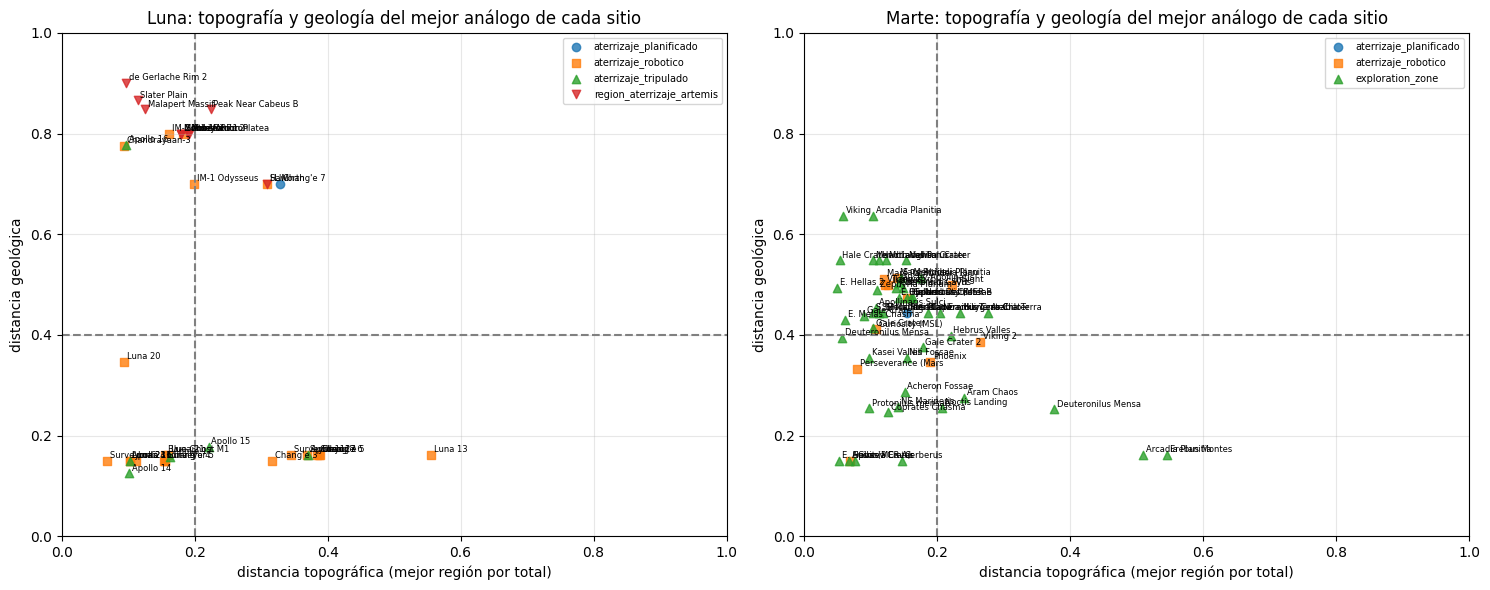

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, cuerpo in zip(axes, ["luna", "marte"]):
    d = res[res.cuerpo == cuerpo]
    for tipo, mk in zip(sorted(d.tipo.unique()), "os^vD"):
        s = d[d.tipo == tipo]
        ax.scatter(s.distancia_topo_total, s.distancia_geo_total, marker=mk, label=tipo, alpha=0.8)
        for r in s.itertuples():
            ax.annotate(str(r.nombre)[:18], (r.distancia_topo_total, r.distancia_geo_total), fontsize=6, xytext=(2, 2), textcoords="offset points")
    ax.axvline(UMBRAL_TOPO, color="grey", ls="--"); ax.axhline(UMBRAL_GEO, color="grey", ls="--")
    ax.set_xlabel("distancia topográfica (mejor región por total)"); ax.set_ylabel("distancia geológica")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    ax.set_title(f"{cuerpo.capitalize()}: topografía y geología del mejor análogo de cada sitio")
plt.tight_layout(); plt.show()

## 9. Capa para la web y registro

In [12]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else round(float(v), 3)
    if isinstance(v, (np.integer,)): return int(v)
    if isinstance(v, (np.bool_,)): return bool(v)
    return v

top5 = pares.dropna(subset=["distancia_total"]).groupby("sitio_id").head(5)
salida = {"version": VERSION,
          "clases": CLASES, "equivalencia_glim": EQUIVALENCIA,
          "umbrales": {"topografia": UMBRAL_TOPO, "geologia": UMBRAL_GEO},
          "unidades": {"distancia_geo": "1 − fracción de roca compartida (0–1)",
                       "distancia_topo": "media de KS de pendiente y de relieve (0–1)",
                       "distancia_total": "media de las dos", "f_*": "fracción del sitio en cada clase común",
                       "quimica": "Luna: % en peso de FeO y TiO2, ppm de Th; Marte: % en peso"},
          "sitios": {r["sitio_id"]: {**{k: limpio(v) for k, v in r.items() if k != "sitio_id"},
                                      "top5_tierra": [{k: limpio(v) for k, v in p.items() if k not in ("sitio_id", "sitio", "tipo_sitio", "cuerpo")}
                                                      for p in top5[top5.sitio_id == r["sitio_id"]].to_dict("records")]}
                     for r in res.to_dict("records")},
          "nota": "unir con 06_web/sitios_v0/sitios.geojson por id; region_id como en topografia_v2/topografia.json"}
json.dump(salida, open(f"{WEB}/geologia_sitios.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, allow_nan=False)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["geologia"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/geologia_sitios.json"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)

registro = {"version": VERSION, "fecha": datetime.datetime.utcnow().isoformat(timespec="minutes") + "Z",
            "fuentes": {"luna_mapa": URLS_LUNA[0], "marte_mapa": FUENTE_MAPA.get("marte"), "marte_trek": TREK_MARTE, "marte_pygeoapi": PYGEOAPI_MARTE,
                        "luna_quimica": URL_LPGRS[0], "marte_quimica": BASE_GRS, "cloruros": URL_CL[0],
                        "tierra": f"{PROCESADOS}/glim_005.nc"},
            "parametros": {"radio_luna_km": RADIO_LUNA_KM, "radio_marte_km": RADIO_MARTE_KM, "radio_analogo_km": RADIO_ANALOGO_KM,
                           "puntos_por_radio": PUNTOS_POR_RADIO, "umbral_topo": UMBRAL_TOPO, "umbral_geo": UMBRAL_GEO,
                           "feo_tierras_altas": FEO_TIERRAS_ALTAS, "feo_mare": FEO_MARE},
            "metricas": {"sitios": int(len(res)),
                         **{f"{c}_completos": f"{int((res[res.cuerpo == c].hay_analogo_completo == 'Sí').sum())}/{int((res.cuerpo == c).sum())}"
                            for c in ["luna", "marte"]},
                         **{f"{c}_solo_topografia": f"{int((res[res.cuerpo == c].parecido_topo_mismo_perfil == 'Sí').sum())}/{int((res.cuerpo == c).sum())}"
                            for c in ["luna", "marte"]},
                         "analogos_conocidos_con_sitio_completo": f"{int((val.sitios_completos > 0).sum())}/{len(val)}",
                         "unidades_sin_clase": {c: [u for u, v in MAPEO[c].items() if not v] for c in MAPEO}},
            "limitaciones": ["mapas a escala 1:5 M (Luna) y 1:20 M (Marte): unidades de decenas de km",
                             "la traducción unidad → clase común → GLiM es una decisión del equipo (tablas editables)",
                             "en la Luna la química es de píxeles de ~60 km",
                             "GLiM no distingue la anortosita como clase propia (va en plutónicas básicas)"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, default=str)
print("✅ Exportado:", json.dumps(registro["metricas"], ensure_ascii=False, indent=1))

/tmp/ipykernel_2372/649780733.py:25: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  registro = {"version": VERSION, "fecha": datetime.datetime.utcnow().isoformat(timespec="minutes") + "Z",


✅ Exportado: {
 "sitios": 97,
 "luna_completos": "14/38",
 "marte_completos": "15/59",
 "luna_solo_topografia": "25/38",
 "marte_solo_topografia": "59/59",
 "analogos_conocidos_con_sitio_completo": "6/15",
 "unidades_sin_clase": {
  "luna": [],
  "marte": []
 }
}


## Notas
- **Orden de ejecución**: `topografia_sitios_v2` (versión con `similitud_sitio_tierra_todas.csv`) → este notebook.
- Archivos: `04_resultados/geologia_v0/` (mapa_unidades_luna.csv, mapa_unidades_marte.csv, equivalencia_clases_glim.csv,
  geologia_sitios.csv, geologia_tierra_glim.csv, similitud_geo_topo.csv, geologia_topografia_sitios.csv,
  analogos_conocidos_geo_topo.csv, registro_geologia_v0.json) y `06_web/geologia_v0/geologia_sitios.json`.